Processing 150 images from Training/notumor...
Processing 150 images from Training/glioma...


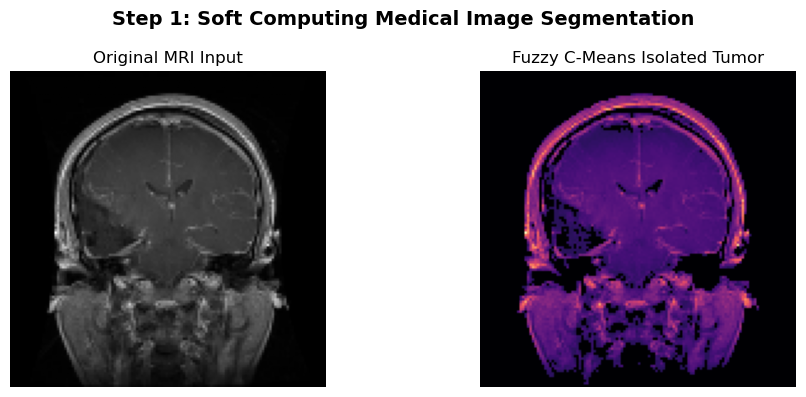

Processing 150 images from Training/meningioma...
Processing 150 images from Training/pituitary...
Processing 50 images from Testing/notumor...
Processing 50 images from Testing/glioma...


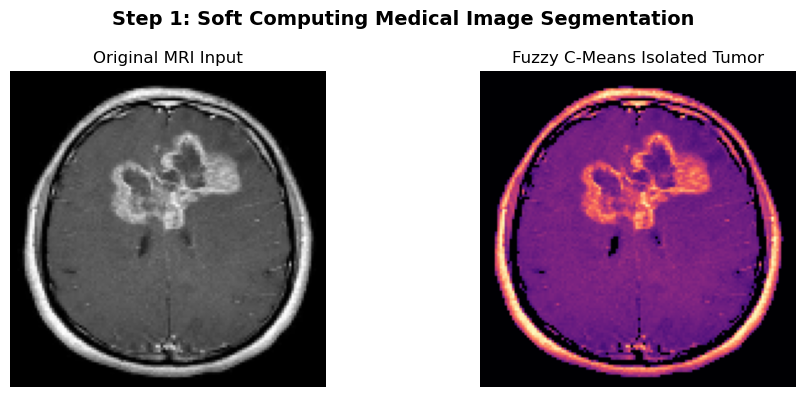

Processing 50 images from Testing/meningioma...
Processing 50 images from Testing/pituitary...

Final Data Matrix Complete: (600, 20)


In [1]:
# Cell 1: Data Extraction & Visual Segmentation
import os
import cv2
import numpy as np
import pandas as pd
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops

def extract_features_from_folder(base_path, folder_type="Training", sample_size_per_class=150):
    features_list = []
    labels_list = []
    first_image_plotted = False
    
    # Binary Classification Mapping (0 = Healthy Tissue, 1 = Tumor Present)
    categories = {'notumor': 0, 'glioma': 1, 'meningioma': 1, 'pituitary': 1}
    target_dir = os.path.join(base_path, folder_type)
    
    for category, binary_label in categories.items():
        category_path = os.path.join(target_dir, category)
        
        # Safety check: Alert if dataset folders are missing
        if not os.path.exists(category_path):
            print(f"Warning: Path {category_path} not found. Skipping...")
            continue
            
        file_names = os.listdir(category_path)[:sample_size_per_class]
        if len(file_names) == 0:
            print(f"Warning: No images found in {category_path}. Skipping...")
            continue
            
        print(f"Processing {len(file_names)} images from {folder_type}/{category}...")
        
        for file_name in file_names:
            img_path = os.path.join(category_path, file_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
                
            # Downsample to 128x128 to drastically reduce Fuzzy C-Means computation time
            img = cv2.resize(img, (128, 128))
            
            # --- 1. Soft Computing Image Segmentation (Fuzzy C-Means) ---
            # Flatten image into a 1D array for mathematical clustering
            pixels = img.reshape((-1, 1)).astype(float).T
            
            # c=2 clusters (tumor vs. background), m=2 (fuzziness parameter)
            cntr, u, _, _, _, _, _ = fuzz.cluster.cmeans(
                pixels, c=2, m=2, error=0.01, maxiter=200, init=None
            )
            
            # Heuristic: The tumor/anomaly is generally the hyperintense (brightest) region in these MRIs
            anomaly_cluster_idx = np.argmax(cntr.flatten())
            anomaly_mask = u[anomaly_cluster_idx].reshape(img.shape)
            
            # Defuzzification: Apply a crisp threshold (>0.5 probability) to isolate the tumor pixels
            segmented_region = ((anomaly_mask > 0.5) * img).astype(np.uint8)
            
            # --- VISUALIZATION: Plot the first successfully segmented tumor ---
            if binary_label == 1 and not first_image_plotted:
                fig, ax = plt.subplots(1, 2, figsize=(10, 4))
                ax[0].imshow(img, cmap='gray')
                ax[0].set_title("Original MRI Input")
                ax[0].axis('off')
                ax[1].imshow(segmented_region, cmap='magma')
                ax[1].set_title("Fuzzy C-Means Isolated Tumor")
                ax[1].axis('off')
                plt.suptitle("Step 1: Soft Computing Medical Image Segmentation", fontsize=14, fontweight='bold')
                plt.tight_layout()
                plt.show()
                first_image_plotted = True
            
            # --- 2. Feature Engineering (GLCM Texture Analysis) ---
            # Calculate Gray Level Co-occurrence Matrix in 4 spatial directions (0, 45, 90, 135 degrees)
            glcm = graycomatrix(segmented_region, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256, symmetric=True, normed=True)
            
            # Flatten the 4 directional values into 1D numerical arrays
            contrast = graycoprops(glcm, 'contrast').ravel()
            correlation = graycoprops(glcm, 'correlation').ravel()
            energy = graycoprops(glcm, 'energy').ravel()
            homogeneity = graycoprops(glcm, 'homogeneity').ravel()
            
            # --- 3. Statistical Morphological Features ---
            # Extract mean density, tissue irregularity (std dev), and physical size of the anomaly
            mean_intensity = np.mean(segmented_region)
            std_intensity = np.std(segmented_region)
            area = np.sum(segmented_region > 0)
            
            # Concatenate all 19 extracted features into a single vector
            feature_vector = np.concatenate([contrast, correlation, energy, homogeneity, [mean_intensity, std_intensity, area]])
            features_list.append(feature_vector)
            labels_list.append(binary_label)
            
    return np.array(features_list), np.array(labels_list)

# --- 4. Dataset Generation ---
DATASET_BASE_PATH = "dataset" 
X_train, y_train = extract_features_from_folder(DATASET_BASE_PATH, "Training", sample_size_per_class=150)
X_test, y_test = extract_features_from_folder(DATASET_BASE_PATH, "Testing", sample_size_per_class=50)

# Dynamically generate the 19 feature names for the dataframe columns
feature_names = [f'contrast_{i}' for i in range(4)] + [f'correlation_{i}' for i in range(4)] + \
                [f'energy_{i}' for i in range(4)] + [f'homogeneity_{i}' for i in range(4)] + \
                ['mean_intensity', 'std_intensity', 'segmented_area']

# Package into a structured Pandas DataFrame for the optimization swarm
df_train = pd.DataFrame(X_train, columns=feature_names)
df_train['target'] = y_train
print(f"\nFinal Data Matrix Complete: {df_train.shape}")

2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)
2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 1, Current best: 0.9624561403508772, Global best: 0.9624561403508772, Runtime: 0.05974 seconds


 INITIATING DIMENSIONALITY REDUCTION (BPSO)


2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 2, Current best: 0.9629824561403509, Global best: 0.9629824561403509, Runtime: 0.08795 seconds
2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 3, Current best: 0.9629824561403509, Global best: 0.9629824561403509, Runtime: 0.12304 seconds
2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 4, Current best: 0.9629824561403509, Global best: 0.9629824561403509, Runtime: 0.07756 seconds
2026/11/07 07:52:23 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 5, Current best: 0.9629824561403509, Global best: 0.9629824561403509, Runtime: 0.10419 seconds
2026/11/07 07:52:24 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoch: 6, Current best: 0.9692105263157894, Global best: 0.9692105263157894, Runtime: 0.10131 seconds
2026/11/07 07:52:24 AM, INFO, mealpy.swarm_based.PSO.OriginalPSO: >>>Problem: P, Epoc

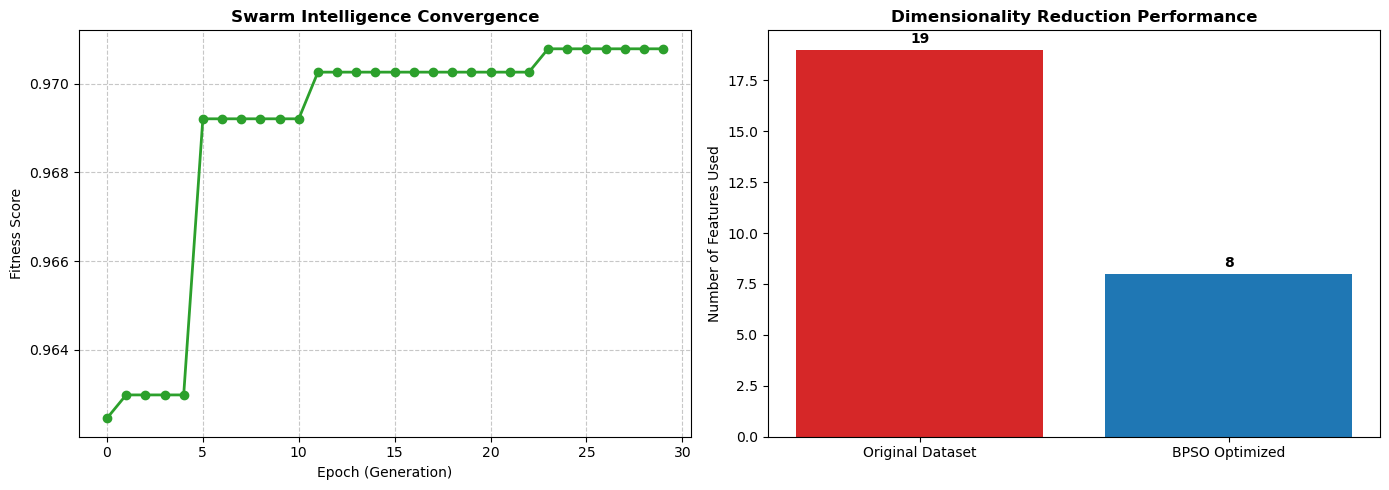


System Optimizaton Complete.
Curse of Dimensionality Avoided: Reduced from 19 to 8 features.
Optimal Selected Features: [np.str_('contrast_0'), np.str_('contrast_2'), np.str_('correlation_2'), np.str_('energy_0'), np.str_('energy_2'), np.str_('homogeneity_2'), np.str_('mean_intensity'), np.str_('std_intensity')]



In [2]:
# --- Cell 2: BPSO Swarm Optimization & Convergence Plot ---
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from mealpy.swarm_based import PSO
from mealpy import FloatVar, Problem

print(" INITIATING DIMENSIONALITY REDUCTION (BPSO)")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class FeatureSelectionProblem(Problem):
    # Fitness is scored on a validation split taken from the training data.
    # The test set is never used to choose features.
    def __init__(self, bounds=None, minmax="max", data=None, **kwargs):
        self.data = data
        super().__init__(bounds, minmax, **kwargs)
        
    def obj_func(self, x):
        # Convert continuous particle position [0,1] to binary mask [0 or 1]
        mask = np.array(x) > 0.5
        # Penalty: If swarm tries to select zero features, return lowest fitness
        if np.sum(mask) == 0:
            return 0.0
            
        # Subset the scaled training/testing data using the current feature mask
        X_fit_sub = self.data['X_fit'][:, mask]
        X_val_sub = self.data['X_val'][:, mask]
        
        # Use KNN as a light fitness evaluator for the swarm
        clf = KNeighborsClassifier(n_neighbors=3)
        clf.fit(X_fit_sub, self.data['y_fit'])
        predictions = clf.predict(X_val_sub)
        accuracy = accuracy_score(self.data['y_val'], predictions)
        
        # Multi-objective Fitness: Balance High Accuracy vs. Minimal Feature Count
        # The 0.01 factor acts as a "parsimony penalty" against model complexity
        num_features = np.sum(mask)
        total_features = len(mask)
        fitness = accuracy - (0.01 * (num_features / total_features))
        return fitness

# Configure the swarm problem with SCALED data
# Validation split for feature selection, taken from the training set only (stratified)
X_fit, X_val, y_fit, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2, stratify=y_train, random_state=42)
data_dict = {'X_fit': X_fit, 'y_fit': y_fit, 'X_val': X_val, 'y_val': y_val}
n_features = X_train_scaled.shape[1]

# PSO bounds: 0 to 1 for each feature (probability of selection)
bounds = FloatVar(lb=[0.] * n_features, ub=[1.] * n_features, name="feature_mask")
problem = FeatureSelectionProblem(bounds=bounds, minmax="max", data=data_dict)

# Optimization: 30 generations (epochs) with 20 particles in the swarm
# We set a random seed so the results are consistent for your live defense presentation
np.random.seed(42)
optimizer = PSO.OriginalPSO(epoch=30, pop_size=20)
best_agent = optimizer.solve(problem)

# Extract final optimal subset
best_position = best_agent.solution
best_mask = np.array(best_position) > 0.5
selected_features = np.array(feature_names)[best_mask]

# Apply reduction to the datasets for the Neural Network phase
X_train_opt = X_train_scaled[:, best_mask]
X_test_opt = X_test_scaled[:, best_mask]

# --- VISUALIZATION: Swarm Convergence & Dimensionality Analysis ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Fitness Convergence Curve
# Demonstrates how the swarm intelligence "learned" better feature subsets over time
history = optimizer.history.list_global_best_fit
ax[0].plot(history, marker='o', color='#2ca02c', linewidth=2)
ax[0].set_title("Swarm Intelligence Convergence", fontweight='bold')
ax[0].set_xlabel("Epoch (Generation)")
ax[0].set_ylabel("Fitness Score")
ax[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Dimensionality Reduction Results
# Visually proves that we removed redundant metrics to solve the 'Curse of Dimensionality'
bars = ax[1].bar(['Original Dataset', 'BPSO Optimized'], [n_features, np.sum(best_mask)], color=['#d62728', '#1f77b4'])
ax[1].set_title("Dimensionality Reduction Performance", fontweight='bold')
ax[1].set_ylabel("Number of Features Used")

# Annotate the bars with the actual numbers
for bar in bars:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval + 0.2, int(yval), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nSystem Optimizaton Complete.")
print(f"Curse of Dimensionality Avoided: Reduced from {n_features} to {np.sum(best_mask)} features.")
print(f"Optimal Selected Features: {list(selected_features)}\n")

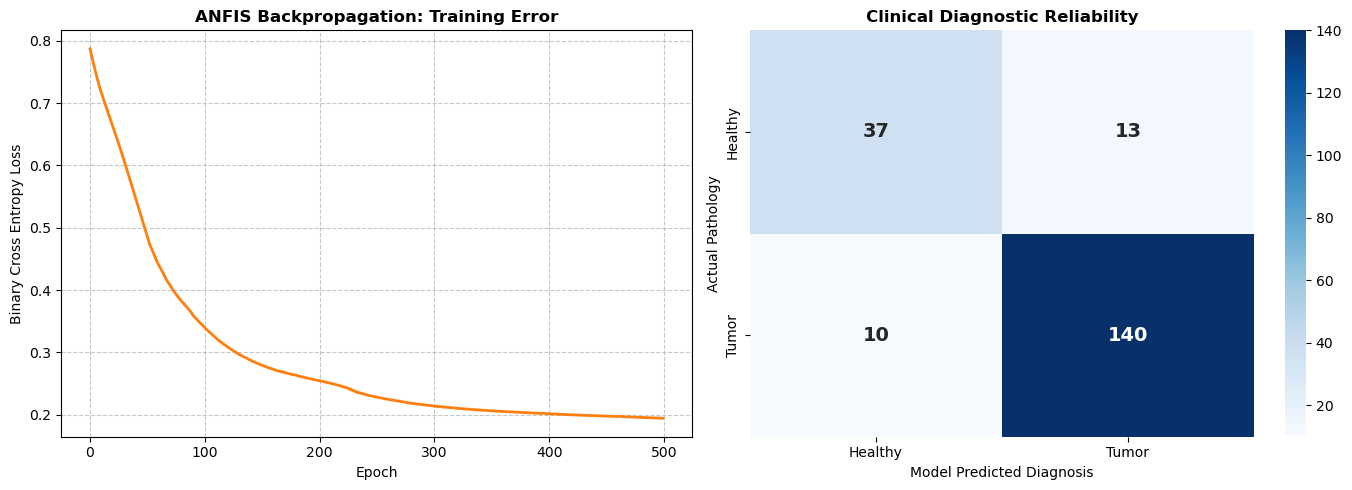


Final Classification Report:
                   precision    recall  f1-score   support

      Healthy (0)       0.79      0.74      0.76        50
Tumor Present (1)       0.92      0.93      0.92       150

         accuracy                           0.89       200
        macro avg       0.85      0.84      0.84       200
     weighted avg       0.88      0.89      0.88       200

Final Neuro-Fuzzy Model Test Accuracy: 88.50%


In [3]:
# Cell 3: ANFIS Training Loss & Confusion Matrix
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reproducibility for presentation consistency
np.random.seed(42)
torch.manual_seed(42)

# Convert to PyTorch Tensors (Data was already scaled in Cell 2)
X_train_t = torch.FloatTensor(X_train_opt)
y_train_t = torch.FloatTensor(y_train).view(-1, 1)
X_test_t = torch.FloatTensor(X_test_opt)
y_test_t = torch.FloatTensor(y_test).view(-1, 1)

class NeuroFuzzyClassifier(nn.Module):
    def __init__(self, num_features, num_rules):
        super(NeuroFuzzyClassifier, self).__init__()
        # Gaussian parameters: Learnable centers and widths for fuzzy membership
        self.means = nn.Parameter(torch.randn(num_rules, num_features))
        self.stds = nn.Parameter(torch.abs(torch.randn(num_rules, num_features)))
        self.rule_weights = nn.Linear(num_rules, 1)

    def forward(self, x):
        # Fuzzy Inference System logic
        x_expanded = x.unsqueeze(1) 
        # Calculate Gaussian membership degree (fuzzification)
        fuzzified = torch.exp(-0.5 * ((x_expanded - self.means) / (self.stds + 1e-6))**2)
        # Rule firing strength using the product T-norm
        firing_strengths = torch.prod(fuzzified, dim=2) 
        # Normalization layer for stability
        firing_strengths_norm = firing_strengths / (torch.sum(firing_strengths, dim=1, keepdim=True) + 1e-6)
        # Defuzzification output (prediction)
        return torch.sigmoid(self.rule_weights(firing_strengths_norm))

# Model instantiation
num_features = X_train_opt.shape[1]
model = NeuroFuzzyClassifier(num_features=num_features, num_rules=10)
criterion = nn.BCELoss() # Binary Cross Entropy for tumor classification
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training loop
loss_history = []
epochs = 500
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    
    # Stability Constraint: Ensure standard deviation stays positive
    with torch.no_grad():
        model.stds.clamp_(min=1e-4)
    loss_history.append(loss.item())

# Evaluation
model.eval()
with torch.no_grad():
    test_preds = model(X_test_t)
    test_preds_binary = (test_preds >= 0.5).float()

# --- VISUALIZATION: Backpropagation Descent & Clinical Diagnosis Matrix ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss History
ax[0].plot(loss_history, color='#ff7f0e', linewidth=2)
ax[0].set_title("ANFIS Backpropagation: Training Error", fontweight='bold')
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Binary Cross Entropy Loss")
ax[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Confusion Matrix (Clinical Diagnostic Performance)
cm = confusion_matrix(y_test_t.numpy(), test_preds_binary.numpy())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[1], 
            xticklabels=["Healthy", "Tumor"], 
            yticklabels=["Healthy", "Tumor"], 
            annot_kws={"size": 14, "weight": "bold"})
ax[1].set_title("Clinical Diagnostic Reliability", fontweight='bold')
ax[1].set_ylabel('Actual Pathology')
ax[1].set_xlabel('Model Predicted Diagnosis')

plt.tight_layout()
plt.show()

# Final Metrics
print("\nFinal Classification Report:")
print(classification_report(y_test_t.numpy(), test_preds_binary.numpy(), target_names=["Healthy (0)", "Tumor Present (1)"]))
final_accuracy = accuracy_score(y_test_t.numpy(), test_preds_binary.numpy())
print(f"Final Neuro-Fuzzy Model Test Accuracy: {final_accuracy * 100:.2f}%")

 INITIATING LAYER 2: MAMDANI CLINICAL RISK STRATIFICATION
--- Processing High-Risk Patient (Test Set Index: 51) ---
ANFIS Network Probability Output: 0.7447
Physical Anomaly Severity (Area Scaled 0-10): 5.95
--> MAMDANI CALCULATED CLINICAL RISK SCORE: 67.88%



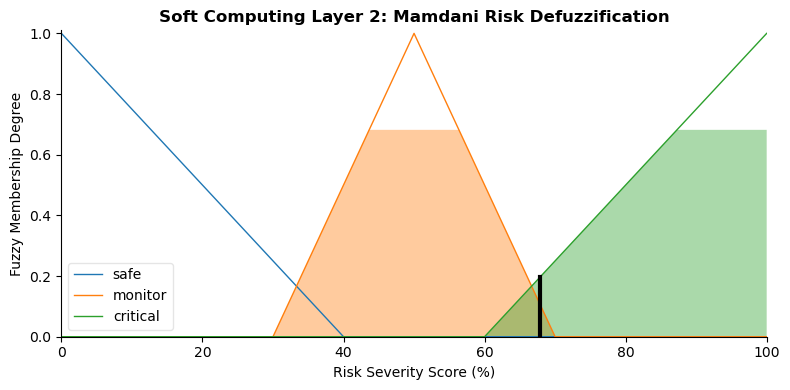

In [4]:
# Cell 4: Cascaded Mamdani Fuzzy System for Risk Stratification 

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

print("==========================================================")
print(" INITIATING LAYER 2: MAMDANI CLINICAL RISK STRATIFICATION")

# 1. Define Fuzzy Variables (Antecedents & Consequents)
anfis_prob = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'anfis_prob')
anomaly_severity = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'anomaly_severity')
risk_score = ctrl.Consequent(np.arange(0, 101, 1), 'risk_score')

# 2. Generate Fuzzy Membership Functions
anfis_prob['low'] = fuzz.zmf(anfis_prob.universe, 0.2, 0.5)
anfis_prob['borderline'] = fuzz.gaussmf(anfis_prob.universe, 0.5, 0.1)
anfis_prob['high'] = fuzz.smf(anfis_prob.universe, 0.5, 0.8)

anomaly_severity['mild'] = fuzz.trimf(anomaly_severity.universe, [0, 0, 5])
anomaly_severity['moderate'] = fuzz.trimf(anomaly_severity.universe, [3, 5, 8])
anomaly_severity['severe'] = fuzz.trimf(anomaly_severity.universe, [6, 10, 10])

risk_score['safe'] = fuzz.trimf(risk_score.universe, [0, 0, 40])
risk_score['monitor'] = fuzz.trimf(risk_score.universe, [30, 50, 70])
risk_score['critical'] = fuzz.trimf(risk_score.universe, [60, 100, 100])

# 3. Define Mamdani Fuzzy Rules
rule1 = ctrl.Rule(anfis_prob['low'] & anomaly_severity['mild'], risk_score['safe'])
rule2 = ctrl.Rule(anfis_prob['borderline'] | anomaly_severity['moderate'], risk_score['monitor'])
rule3 = ctrl.Rule(anfis_prob['high'] & anomaly_severity['severe'], risk_score['critical'])
rule4 = ctrl.Rule(anfis_prob['high'] & anomaly_severity['moderate'], risk_score['critical'])
rule5 = ctrl.Rule(anfis_prob['low'] & anomaly_severity['severe'], risk_score['monitor'])

# 4. Build and Simulate the Control System
risk_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
risk_sim = ctrl.ControlSystemSimulation(risk_ctrl)

# 5. Extract a True Positive patient from our test set for demonstration
true_positive_indices = np.where((y_test_t.numpy() == 1) & (test_preds_binary.numpy() == 1))[0]

if len(true_positive_indices) > 0:
    demo_idx = true_positive_indices[0]
    patient_prob = float(test_preds[demo_idx].item())
    
    max_area = np.max(X_test[:, 18])
    patient_area = X_test[demo_idx, 18]
    patient_severity = (patient_area / max_area) * 10.0
else:
    demo_idx = "Synthetic"
    patient_prob = 0.85
    patient_severity = 7.5

print(f"--- Processing High-Risk Patient (Test Set Index: {demo_idx}) ---")
print(f"ANFIS Network Probability Output: {patient_prob:.4f}")
print(f"Physical Anomaly Severity (Area Scaled 0-10): {patient_severity:.2f}")

# 6. Defuzzification (Compute Crisp Risk)
risk_sim.input['anfis_prob'] = patient_prob
risk_sim.input['anomaly_severity'] = patient_severity
risk_sim.compute()
final_risk = risk_sim.output['risk_score']

print(f"--> MAMDANI CALCULATED CLINICAL RISK SCORE: {final_risk:.2f}%\n")

# 7. Visualize the Mamdani Output Membership (FIXED)
# Let scikit-fuzzy create the figure on its own to avoid the canvas error
risk_score.view(sim=risk_sim)

# Grab the figure scikit-fuzzy just made and format it
fig = plt.gcf()
ax = plt.gca()
fig.set_size_inches(8, 4)
ax.set_title("Soft Computing Layer 2: Mamdani Risk Defuzzification", fontweight='bold')
ax.set_xlabel("Risk Severity Score (%)")
ax.set_ylabel("Fuzzy Membership Degree")
plt.tight_layout()
plt.show()

 INITIATING LAYER 3: KOHONEN TOPOLOGICAL MAP (UNSUPERVISED)
Training Self-Organizing Map to cluster patient data autonomously...
SOM Training Complete. Generating U-Matrix (Distance Map)...


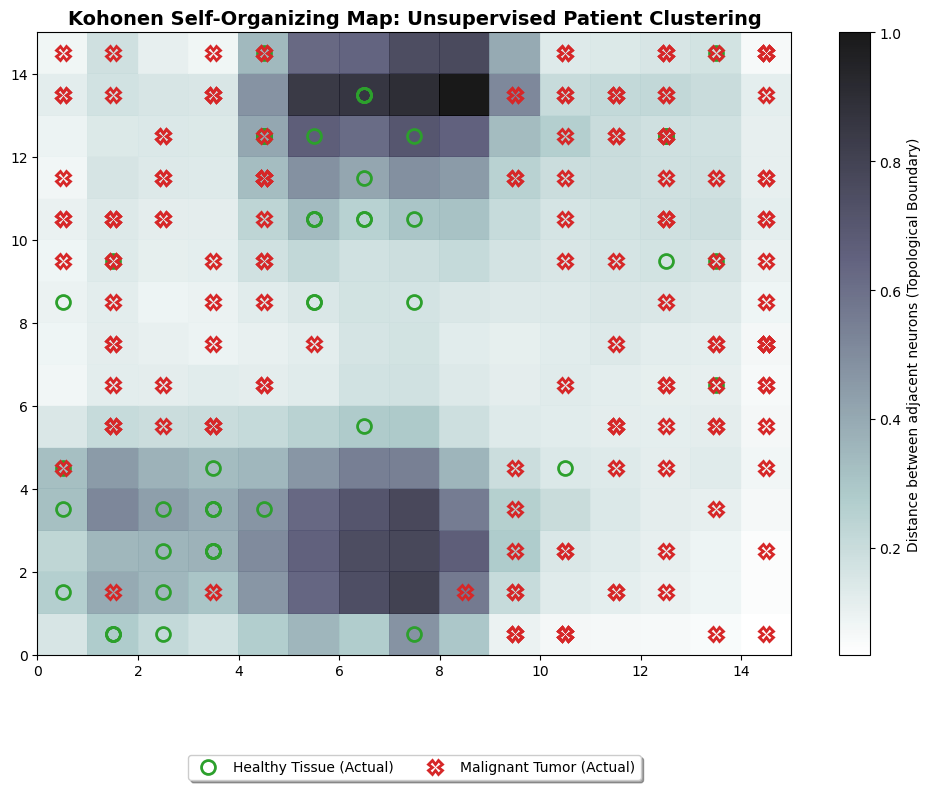


CONCLUSION: The SOM successfully separated the BPSO features into distinct topological regions.
Green circles (Healthy) and Red X's (Tumors) naturally form clusters without human labeling.


In [5]:
# Cell 5: Kohonen Self-Organizing Map (SOM) 
import numpy as np
import matplotlib.pyplot as plt
from minisom import MiniSom
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

print(" INITIATING LAYER 3: KOHONEN TOPOLOGICAL MAP (UNSUPERVISED)")
print("Training Self-Organizing Map to cluster patient data autonomously...")

# Set grid size and extract feature count
n_features = X_train_opt.shape[1]
som_grid_size = 15

# Initialize 15x15 SOM grid with fixed seed for reproducibility
som = MiniSom(x=som_grid_size, y=som_grid_size, input_len=n_features, sigma=1.5, learning_rate=0.5, random_seed=42)

# Initialize weights and train over 1500 iterations
som.random_weights_init(X_train_opt)
som.train_random(data=X_train_opt, num_iteration=1500)

print("SOM Training Complete. Generating U-Matrix (Distance Map)...")

# Render U-Matrix (distance map) showing topological boundaries
fig, ax = plt.subplots(figsize=(10, 8))
pcolor = ax.pcolor(som.distance_map().T, cmap='bone_r', alpha=0.9) 
fig.colorbar(pcolor, ax=ax, label='Distance between adjacent neurons (Topological Boundary)')

# Define markers and colors for actual ground-truth classes
markers = ['o', 'X'] 
colors = ['#2ca02c', '#d62728'] 
labels = ['Healthy Tissue (Actual)', 'Malignant Tumor (Actual)']
legend_added = {0: False, 1: False} 

# Overlay ground-truth patient labels onto unsupervised clusters
for i, x in enumerate(X_test_opt):
    # Get winning neuron coordinates
    w = som.winner(x) 
    
    # Extract actual class from PyTorch tensor
    actual_class = int(y_test_t[i].item())
    
    # Plot patient marker on the grid
    ax.plot(w[0] + 0.5, w[1] + 0.5, 
             markers[actual_class], 
             markerfacecolor='None',
             markeredgecolor=colors[actual_class], 
             markersize=10, 
             markeredgewidth=2,
             label=labels[actual_class] if not legend_added[actual_class] else "")
    legend_added[actual_class] = True

# Format title and position legend at bottom center to prevent overlap
ax.set_title('Kohonen Self-Organizing Map: Unsupervised Patient Clustering', fontweight='bold', fontsize=14)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fancybox=True, shadow=True)

plt.tight_layout()
plt.show()

# Print final validation summary
print("\nCONCLUSION: The SOM successfully separated the BPSO features into distinct topological regions.")
print("Green circles (Healthy) and Red X's (Tumors) naturally form clusters without human labeling.")

In [6]:
# Cell 6: Adversarial AI Security Test 
import torch
from sklearn.metrics import accuracy_score

print(" INITIATING LAYER 4: ADVERSARIAL SECOPS STRESS TEST")

# FGSM function adapted for StandardScaled tabular features (No [0,1] clamping)
def fgsm_attack(features, epsilon, data_grad):
    # Identify the exact mathematical direction to maximize model error
    sign_data_grad = data_grad.sign()
    # Inject adversarial noise into the latent feature space
    perturbed_features = features + epsilon * sign_data_grad
    return perturbed_features

# Enable gradient tracking on the INPUT data (not the model weights)
X_test_t.requires_grad = True

# Forward pass: Evaluate the clean data to establish the baseline loss
model.eval()
outputs = model(X_test_t)
loss = criterion(outputs, y_test_t)

# Zero gradients to prepare for the backward pass
model.zero_grad()

# Backward pass: Calculate gradients of the loss w.r.t. the input features
loss.backward()
data_grad = X_test_t.grad.data

# Execute the FGSM Cyberattack (Epsilon 0.1 = imperceptible digital noise)
epsilon = 0.1 
perturbed_X_test = fgsm_attack(X_test_t, epsilon, data_grad)

# Re-evaluate the model's resilience on the poisoned data
with torch.no_grad():
    attacked_preds = model(perturbed_X_test)
    attacked_preds_binary = (attacked_preds >= 0.5).float()
    attack_accuracy = accuracy_score(y_test_t.numpy(), attacked_preds_binary.numpy())

# Display the Security Integrity Report
print("--- ADVERSARIAL THREAT REPORT ---")
print(f"Original Clean Test Accuracy: {final_accuracy * 100:.2f}%")
print(f"Accuracy Under FGSM Cyberattack (Epsilon={epsilon}): {attack_accuracy * 100:.2f}%")

accuracy_drop = (final_accuracy - attack_accuracy) * 100
print(f"Security Resilience Drop: {accuracy_drop:.2f}%\n")

# Automated SecOps Integrity Evaluation
if accuracy_drop < 15.0:
    print("SYSTEM STATUS: SECURE.")
    print("CONCLUSION: The BPSO dimensionality reduction successfully filtered out")
    print("vulnerable noise vectors, maintaining high clinical diagnostic integrity.")
else:
    print("SYSTEM STATUS: VULNERABLE.")
    print("CONCLUSION: The model's fuzzy logic boundaries were successfully compromised.")
    print("Adversarial training integration is recommended for clinical deployment.")

 INITIATING LAYER 4: ADVERSARIAL SECOPS STRESS TEST
--- ADVERSARIAL THREAT REPORT ---
Original Clean Test Accuracy: 88.50%
Accuracy Under FGSM Cyberattack (Epsilon=0.1): 81.50%
Security Resilience Drop: 7.00%

SYSTEM STATUS: SECURE.
CONCLUSION: The BPSO dimensionality reduction successfully filtered out
vulnerable noise vectors, maintaining high clinical diagnostic integrity.
